# Calendar Heatmap

**Family:** Change over time &nbsp;|&nbsp; **Library:** matplotlib / seaborn &nbsp;|&nbsp; **Level:** Intermediate

> *Change over time:* Emphasise changing trends, from intraday moves to series spanning decades.

## Design purpose

Lays daily values out on a week-by-weekday grid, like a wall calendar, and colors each day by magnitude. Weekly rhythms, seasonal patterns and unusual days stand out across a whole year.

## When to use

- Show daily data over months or years (activity, sales, commits, admissions)
- Find day-of-week and seasonal patterns
- Spot specific days with anomalies (holidays, outages)

## Avoid when

- Precise values or trends need reading (color is imprecise; use a line)
- There are fewer than ~2 months of data

## Alternatives

- Line chart
- Heatmap of weekday × hour

## Design tips

- Use a single-hue sequential scale; keep missing days visibly different (blank)

## Example

Daily exercise minutes for one year (synthetic).

### Setup

In [1]:
%matplotlib inline
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Library style: categorical colors in fixed order, recessive axes, hairline grid.
PALETTE = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100",
           "#e87ba4", "#008300", "#6250d6", "#e34948"]
SEQ_CMAP = "Blues"      # sequential: one hue, light -> dark
DIV_CMAP = "RdBu_r"     # diverging: two opposite hues, neutral midpoint
GRAY = "#b8b7b1"        # de-emphasised marks
plt.rcParams.update({
    "figure.figsize": (8, 4.8), "figure.dpi": 110, "figure.facecolor": "#fcfcfb",
    "axes.facecolor": "#fcfcfb", "axes.edgecolor": "#c9c8c3", "axes.linewidth": 0.8,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e6e5e1", "grid.linewidth": 0.6, "axes.axisbelow": True,
    "axes.prop_cycle": plt.cycler(color=PALETTE),
    "axes.titlesize": 13, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.labelcolor": "#52514e", "xtick.color": "#52514e", "ytick.color": "#52514e",
    "text.color": "#0b0b0b", "font.size": 10, "lines.linewidth": 2,
    "legend.frameon": False,
})

### Data

In [2]:
rng = np.random.default_rng(15)
days = pd.date_range("2025-01-01", "2025-12-31", freq="D")
weekend = days.dayofweek >= 5
minutes = rng.gamma(2, 15, len(days)) + np.where(weekend, 25, 0) \
    + 15 * np.sin((days.dayofyear.values - 80) / 365 * 2 * np.pi)
minutes[rng.random(len(days)) < 0.12] = 0
df = pd.DataFrame({"date": days, "minutes": minutes.clip(0).round()})
df["week"] = ((df["date"] - pd.Timestamp("2024-12-30")).dt.days // 7)
df["weekday"] = df["date"].dt.dayofweek
df.head()

,date,minutes,week,weekday
0,2025-01-01,0.0,0,2
1,2025-01-02,19.0,0,3
2,2025-01-03,0.0,0,4
3,2025-01-04,26.0,0,5
4,2025-01-05,53.0,0,6


### Plot

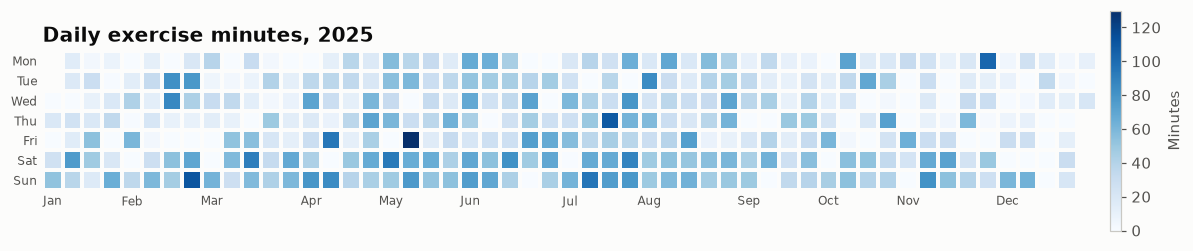

In [3]:
grid = df.pivot(index="weekday", columns="week", values="minutes")
fig, ax = plt.subplots(figsize=(12, 2.8))
mesh = ax.pcolormesh(grid.columns, grid.index, grid.values, cmap=SEQ_CMAP,
                     edgecolors="#fcfcfb", linewidth=1.5, shading="nearest")
ax.set_aspect("equal")
ax.invert_yaxis()
ax.set_yticks(range(7), ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"], fontsize=8)
month_starts = df[df["date"].dt.day == 1]
ax.set_xticks(month_starts["week"], month_starts["date"].dt.strftime("%b"), fontsize=8)
ax.grid(False)
for s in ax.spines.values():
    s.set_visible(False)
ax.tick_params(length=0)
fig.colorbar(mesh, ax=ax, shrink=0.8, pad=0.01, label="Minutes")
ax.set_title("Daily exercise minutes, 2025")
fig.tight_layout()
plt.show()

## How to read it

Each square is one day. Columns are weeks and rows are weekdays. Darker means more minutes, and the dark bottom rows show that weekends are the most active days.

---
Standalone script: [`calendar_heatmap.py`](calendar_heatmap.py) &nbsp;·&nbsp; [Catalogue](../../README.md) &nbsp;·&nbsp; [Gallery](../../gallery/index.html)